<a href="https://colab.research.google.com/github/theochi/MachineLearning/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

***Setup***

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.patches import Rectangle

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.metrics import silhouette_score, accuracy_score
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42

CLUSTER_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
NOISE_COLOR = '#3d3d3a'
SEQ_BLUE = LinearSegmentedColormap.from_list('seq_blue', ['#cde2fb', '#86b6ef', '#2a78d6', '#1c5cab', '#0d366b'])
plt.rcParams.update({'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#c3c2b7', 'axes.spines.top': False, 'axes.spines.right': False,
                     'lines.linewidth': 2, 'figure.dpi': 100})

wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name='cultivar')
print('Feature names:', list(wine.feature_names))
print('Target classes:', list(wine.target_names))

Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


***Task 1***

Dataset dimensions: 178 samples x 13 features
Samples per cultivar (for reference only): {0: 59, 1: 71, 2: 48}

Feature Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


Missing values per feature:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total missing values in dataset: 0
Means after scaling (should be ~0):
{'alcohol': 0.0, 'malic_acid': 0.0, 'ash': -0.0, 'alcalinity_of_ash': -0.0, 'magnesium': -0.0, 'total_phenols': -0.0, 'flavanoids': 0.0, 'nonflavanoid_phenols': -0.0, 'proanthocyanins': -0.0, 'color_intensity': -0.0, 'hue': 0.0, 'od280/od315_of_diluted_wines': 0.0, 'proline': -0.0}

Std devs after scaling (should be ~1):
{'alcohol': 1.0, 'malic_acid': 1.0, 'ash': 1.0, 'alcalinity_of_ash': 1.0, 'magnesium': 1.0, 'total_phenols': 1.0, 'flavano

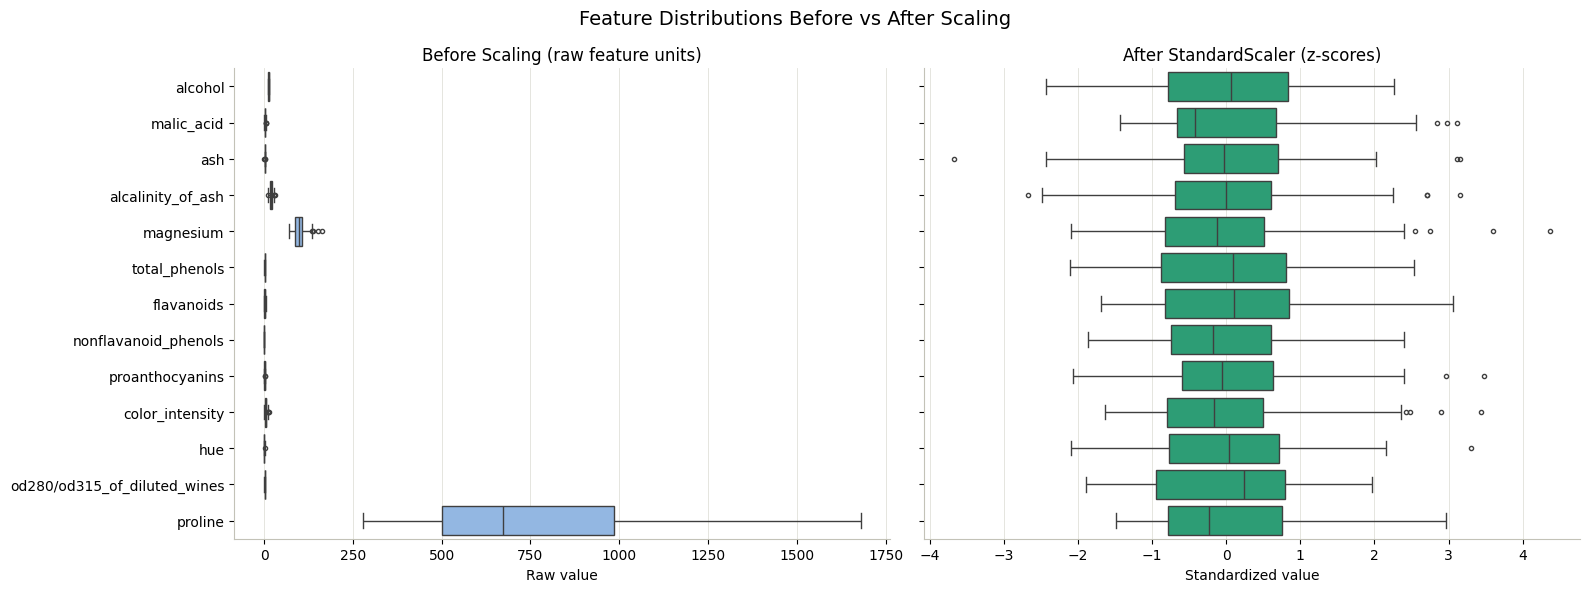

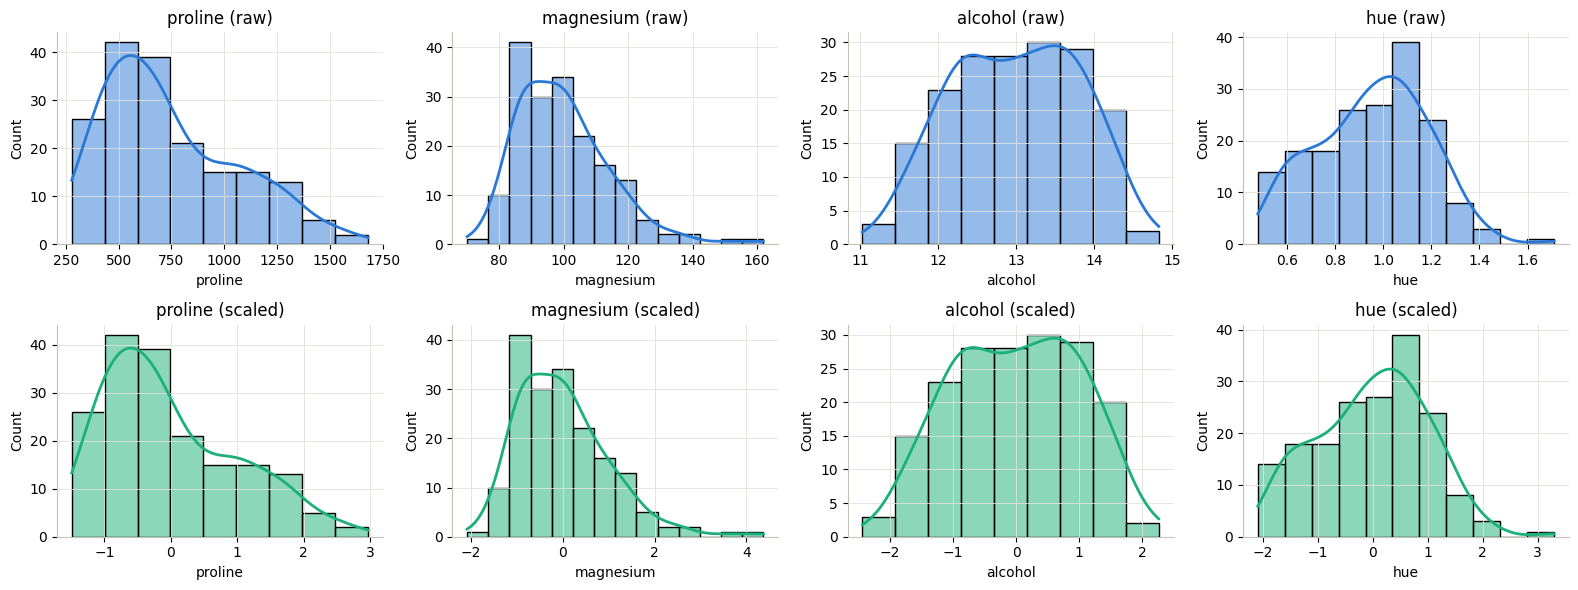

In [2]:
print(f'Dataset dimensions: {X.shape[0]} samples x {X.shape[1]} features')
print('Samples per cultivar (for reference only):', y.value_counts().sort_index().to_dict())

print('\nFeature Summary Statistics:')
display(X.describe().T.round(3))

print('Missing values per feature:')
print(X.isnull().sum())
print(f'\nTotal missing values in dataset: {X.isnull().sum().sum()}')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=wine.feature_names)

print('Means after scaling (should be ~0):')
print(X_scaled_df.mean().round(4).to_dict())
print('\nStd devs after scaling (should be ~1):')
print(X_scaled_df.std(ddof=0).round(4).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=X, orient='h', ax=axes[0], color='#86b6ef', fliersize=3)
axes[0].set_title('Before Scaling (raw feature units)')
axes[0].set_xlabel('Raw value')
sns.boxplot(data=X_scaled_df, orient='h', ax=axes[1], color='#1baf7a', fliersize=3)
axes[1].set_title('After StandardScaler (z-scores)')
axes[1].set_xlabel('Standardized value')
axes[1].set_yticklabels([])
plt.suptitle('Feature Distributions Before vs After Scaling', fontsize=14)
plt.tight_layout()
plt.show()

feats = ['proline', 'magnesium', 'alcohol', 'hue']
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i, f in enumerate(feats):
    sns.histplot(X[f], kde=True, ax=axes[0, i], color='#2a78d6')
    axes[0, i].set_title(f'{f} (raw)')
    sns.histplot(X_scaled_df[f], kde=True, ax=axes[1, i], color='#1baf7a')
    axes[1, i].set_title(f'{f} (scaled)')
plt.tight_layout()
plt.show()

Summary:
This code cell inspects the data (178 × 13, no missing values) and standardizes every feature to mean 0 and standard deviaton 1.

***Task 2***

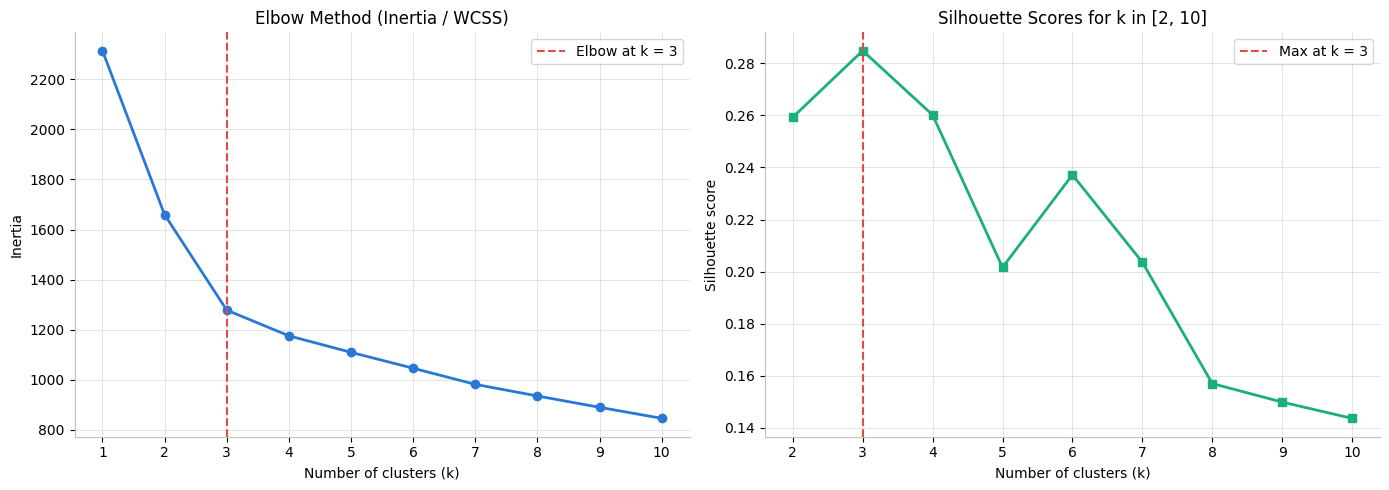

Inertia by k: {1: 2314.0, 2: 1658.8, 3: 1277.9, 4: 1175.4, 5: 1109.5, 6: 1046.0, 7: 981.6, 8: 935.2, 9: 889.9, 10: 845.9}
Silhouette by k: {2: np.float64(0.2593), 3: np.float64(0.2849), 4: np.float64(0.2602), 5: np.float64(0.2016), 6: np.float64(0.2372), 7: np.float64(0.2036), 8: np.float64(0.157), 9: np.float64(0.1499), 10: np.float64(0.1436)}

Optimal k suggested by the Elbow Method:     k = 3
Optimal k suggested by the Silhouette Score: k = 3 (score = 0.2849)


In [3]:
k_values = range(1, 11)
inertia = []
sil_k_values = range(2, 11)
silhouette_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    if k >= 2:
        silhouette_scores.append(silhouette_score(X_scaled, labels))

k_arr, in_arr = np.array(list(k_values)), np.array(inertia)
x_n = (k_arr - k_arr.min()) / (k_arr.max() - k_arr.min())
y_n = (in_arr - in_arr.min()) / (in_arr.max() - in_arr.min())
elbow_k = int(k_arr[np.argmax(np.abs((1 - x_n) - y_n))])

silhouette_k = int(list(sil_k_values)[int(np.argmax(silhouette_scores))])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(k_values, inertia, marker='o', color='#2a78d6')
ax1.axvline(elbow_k, color='#e34948', linestyle='--', linewidth=1.5, label=f'Elbow at k = {elbow_k}')
ax1.set_title('Elbow Method (Inertia / WCSS)')
ax1.set_xlabel('Number of clusters (k)'); ax1.set_ylabel('Inertia')
ax1.set_xticks(list(k_values)); ax1.legend()

ax2.plot(sil_k_values, silhouette_scores, marker='s', color='#1baf7a')
ax2.axvline(silhouette_k, color='#e34948', linestyle='--', linewidth=1.5, label=f'Max at k = {silhouette_k}')
ax2.set_title('Silhouette Scores for k in [2, 10]')
ax2.set_xlabel('Number of clusters (k)'); ax2.set_ylabel('Silhouette score')
ax2.set_xticks(list(sil_k_values)); ax2.legend()
plt.tight_layout()
plt.show()

print('Inertia by k:', {k: round(v, 1) for k, v in zip(k_values, inertia)})
print('Silhouette by k:', {k: round(v, 4) for k, v in zip(sil_k_values, silhouette_scores)})
print(f'\nOptimal k suggested by the Elbow Method:     k = {elbow_k}')
print(f'Optimal k suggested by the Silhouette Score: k = {silhouette_k} (score = {max(silhouette_scores):.4f})')

Summary:
K-Means is run for k = 1–10 and two model-selection criteria are compared. The Elbow curve tracks inertia and the bend marks where adding clusters stops paying off. The Silhouette score measures how well-separated the clusters are; the higher the better. Both metrics point to k = 3, which matches the 3 cultivars.

***Task 3***

Explained variance ratio: PC1 = 0.362, PC2 = 0.192, total = 0.554


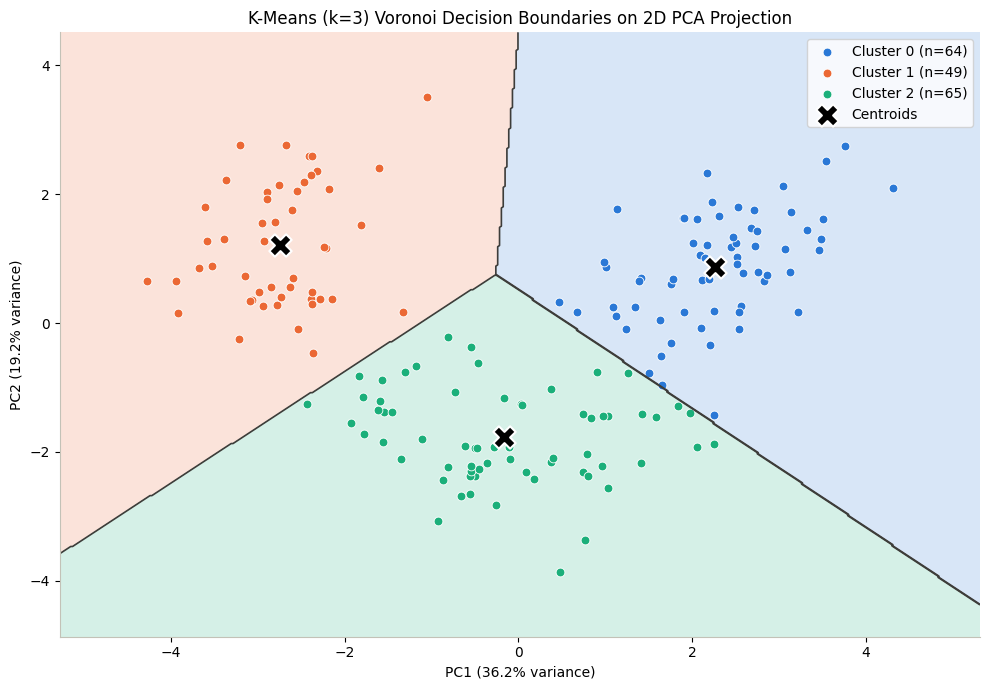

In [4]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f'Explained variance ratio: PC1 = {pca.explained_variance_ratio_[0]:.3f}, '
      f'PC2 = {pca.explained_variance_ratio_[1]:.3f}, total = {pca.explained_variance_ratio_.sum():.3f}')

kmeans_2d = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
labels_2d = kmeans_2d.fit_predict(X_pca)
centroids_2d = kmeans_2d.cluster_centers_

x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))
Z = kmeans_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

cmap3 = ListedColormap(CLUSTER_COLORS[:3])
plt.figure(figsize=(10, 7))
plt.contourf(xx, yy, Z, alpha=0.18, cmap=cmap3, levels=[-0.5, 0.5, 1.5, 2.5])
plt.contour(xx, yy, Z, colors='#3d3d3a', linewidths=1.2, levels=[0.5, 1.5])
for c in range(3):
    m = labels_2d == c
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=40, color=CLUSTER_COLORS[c], edgecolor='white', linewidth=0.6,
                label=f'Cluster {c} (n={m.sum()})')
plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker='X', s=260, c='black', edgecolor='white', linewidth=1.5,
            label='Centroids')
plt.title('K-Means (k=3) Voronoi Decision Boundaries on 2D PCA Projection')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.legend(loc='best')
plt.grid(False)
plt.tight_layout()
plt.show()

Summary:
PCA compresses the 13 scaled features into 2 components. K-Means (k=3) is fitted in that 2D space, and every point on a grid is assigned to its nearest centroid.

***Task 4***

Distance matrix (Euclidean distance in 13-D scaled space):


,Centroid 0,Centroid 1,Centroid 2,Hard assignment
Sample 106 (core),1.548,4.268,4.305,0
Sample 148 (core),4.495,1.079,5.298,1
Sample 48 (core),3.815,4.869,1.343,2
Sample 61 (borderline),3.521,3.397,5.250,1
Sample 121 (borderline),6.327,7.476,6.162,2


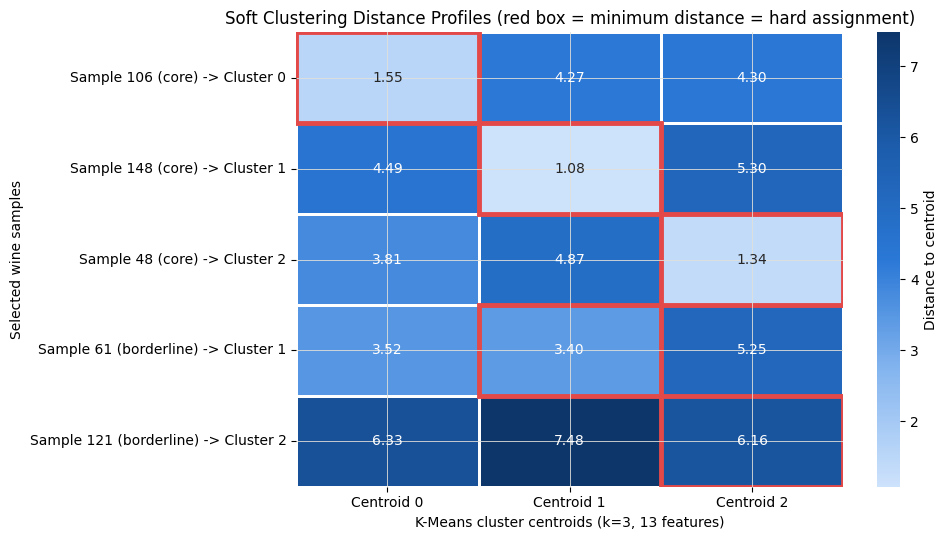

In [5]:
kmeans_13d = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans_13d.fit_predict(X_scaled)

all_dist = kmeans_13d.transform(X_scaled)

core_idx = [int(np.argmin(all_dist[:, c])) for c in range(3)]
sorted_d = np.sort(all_dist, axis=1)
margin = sorted_d[:, 1] - sorted_d[:, 0]
border_idx = [int(i) for i in np.argsort(margin) if i not in core_idx][:2]
sample_idx = core_idx + border_idx
sample_type = ['core'] * 3 + ['borderline'] * 2

dist_matrix = kmeans_13d.transform(X_scaled[sample_idx])
hard_assign = kmeans_13d.predict(X_scaled[sample_idx])

dist_df = pd.DataFrame(dist_matrix, columns=[f'Centroid {c}' for c in range(3)],
                       index=[f'Sample {i} ({t})' for i, t in zip(sample_idx, sample_type)])
dist_df['Hard assignment'] = hard_assign
print('Distance matrix (Euclidean distance in 13-D scaled space):')
display(dist_df.round(3))

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(dist_matrix, annot=True, fmt='.2f', cmap=SEQ_BLUE, cbar_kws={'label': 'Distance to centroid'},
            xticklabels=[f'Centroid {c}' for c in range(3)],
            yticklabels=[f'Sample {i} ({t}) -> Cluster {a}' for i, t, a in zip(sample_idx, sample_type, hard_assign)],
            linewidths=2, linecolor='white', ax=ax)
for r, c in enumerate(np.argmin(dist_matrix, axis=1)):
    ax.add_patch(Rectangle((c, r), 1, 1, fill=False, edgecolor='#e34948', linewidth=3.5))
ax.set_title('Soft Clustering Distance Profiles (red box = minimum distance = hard assignment)')
ax.set_xlabel('K-Means cluster centroids (k=3, 13 features)')
ax.set_ylabel('Selected wine samples')
plt.tight_layout()
plt.show()

Summary:
Using the 13-feature K-Means model, transform() returns each sample's distance to all 3 centroids. The red box marks the smallest distance, which is the sample's hard assignment. Core samples are clearly close to one centroid.

***Task 5***

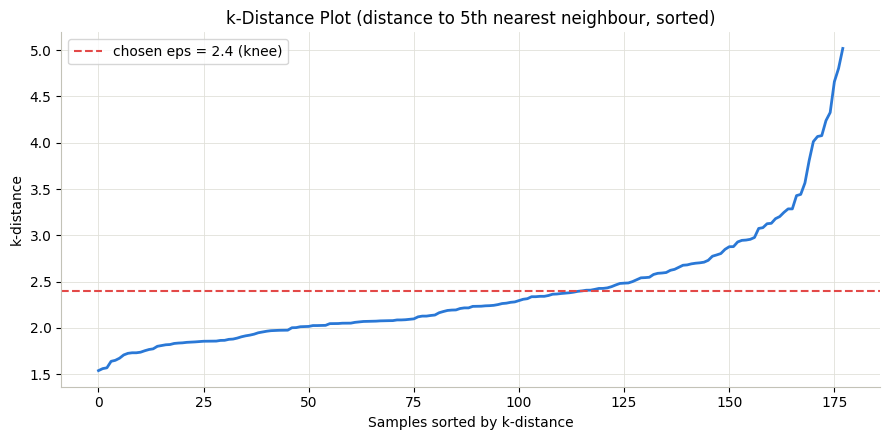

DBSCAN hyperparameter experiment (eps x min_samples):


,eps,min_samples,clusters,noise points,silhouette (non-noise)
0,0.5,3,0,178,NaN
1,0.5,5,0,178,NaN
2,0.5,10,0,178,NaN
3,1.5,3,8,147,0.331
4,1.5,5,0,178,NaN
5,1.5,10,0,178,NaN
6,2.0,3,5,64,0.211
7,2.0,5,5,85,0.240
8,2.0,10,1,139,NaN
9,2.2,3,3,44,0.073


DBSCAN (eps=2.4, min_samples=5)
Number of clusters identified: 2
Number of noise points:        36
Cluster sizes: {-1: 36, 0: 99, 1: 43}


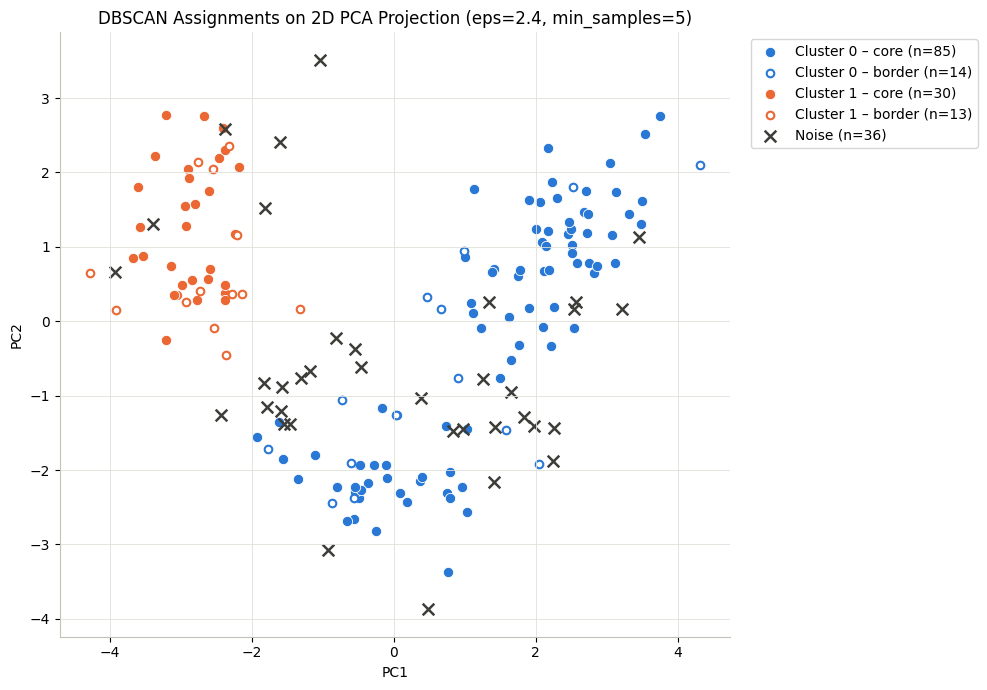

In [6]:
min_samples_ref = 5
nn = NearestNeighbors(n_neighbors=min_samples_ref).fit(X_scaled)
k_dist = np.sort(nn.kneighbors(X_scaled)[0][:, -1])

plt.figure(figsize=(9, 4.5))
plt.plot(k_dist, color='#2a78d6')
plt.axhline(2.4, color='#e34948', linestyle='--', linewidth=1.5, label='chosen eps = 2.4 (knee)')
plt.title(f'k-Distance Plot (distance to {min_samples_ref}th nearest neighbour, sorted)')
plt.xlabel('Samples sorted by k-distance'); plt.ylabel('k-distance')
plt.legend(); plt.tight_layout(); plt.show()

results = []
for eps in [0.5, 1.5, 2.0, 2.2, 2.4, 2.6, 3.0]:
    for ms in [3, 5, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        n_noise = int((lab == -1).sum())
        mask = lab != -1
        sil = silhouette_score(X_scaled[mask], lab[mask]) if n_cl >= 2 else np.nan
        results.append({'eps': eps, 'min_samples': ms, 'clusters': n_cl, 'noise points': n_noise,
                        'silhouette (non-noise)': round(sil, 3) if not np.isnan(sil) else None})
print('DBSCAN hyperparameter experiment (eps x min_samples):')
display(pd.DataFrame(results))

DB_EPS, DB_MIN_SAMPLES = 2.4, 5
dbscan = DBSCAN(eps=DB_EPS, min_samples=DB_MIN_SAMPLES)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_db_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_db_noise = int((dbscan_labels == -1).sum())
print(f'DBSCAN (eps={DB_EPS}, min_samples={DB_MIN_SAMPLES})')
print(f'Number of clusters identified: {n_db_clusters}')
print(f'Number of noise points:        {n_db_noise}')
print('Cluster sizes:', pd.Series(dbscan_labels).value_counts().sort_index().to_dict())

core_mask = np.zeros_like(dbscan_labels, dtype=bool)
core_mask[dbscan.core_sample_indices_] = True

def plot_density_clusters(labels, title, core_mask=None):
    plt.figure(figsize=(10, 7))
    for c in sorted(set(labels) - {-1}):
        m = labels == c
        if core_mask is not None:
            plt.scatter(X_pca[m & core_mask, 0], X_pca[m & core_mask, 1], s=55, color=CLUSTER_COLORS[c],
                        edgecolor='white', linewidth=0.6, label=f'Cluster {c} – core (n={(m & core_mask).sum()})')
            plt.scatter(X_pca[m & ~core_mask, 0], X_pca[m & ~core_mask, 1], s=30, facecolor='white',
                        edgecolor=CLUSTER_COLORS[c], linewidth=1.5, label=f'Cluster {c} – border (n={(m & ~core_mask).sum()})')
        else:
            plt.scatter(X_pca[m, 0], X_pca[m, 1], s=50, color=CLUSTER_COLORS[c], edgecolor='white',
                        linewidth=0.6, label=f'Cluster {c} (n={m.sum()})')
    nm = labels == -1
    plt.scatter(X_pca[nm, 0], X_pca[nm, 1], s=70, marker='x', color=NOISE_COLOR, linewidth=1.8,
                label=f'Noise (n={nm.sum()})')
    plt.title(title)
    plt.xlabel('PC1'); plt.ylabel('PC2')
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout(); plt.show()

plot_density_clusters(dbscan_labels, f'DBSCAN Assignments on 2D PCA Projection (eps={DB_EPS}, min_samples={DB_MIN_SAMPLES})',
                     core_mask=core_mask)

Summary:
DBSCAN groups points that sit in dense neighbourhoods. The default-style eps = 0.5 labels every wine as noise because distances in 13-D space are large, so a k-distance plot and a grid experiment were used to pick eps = 2.4, min_samples = 5. DBSCAN finds 2 dense clusters plus noise (black ×); it struggles to split all 3 cultivars.

***Task 6***

HDBSCAN (min_cluster_size=5)
Total clusters discovered: 2
Noise points detected:     58
Cluster sizes: {-1: 58, 0: 86, 1: 34}


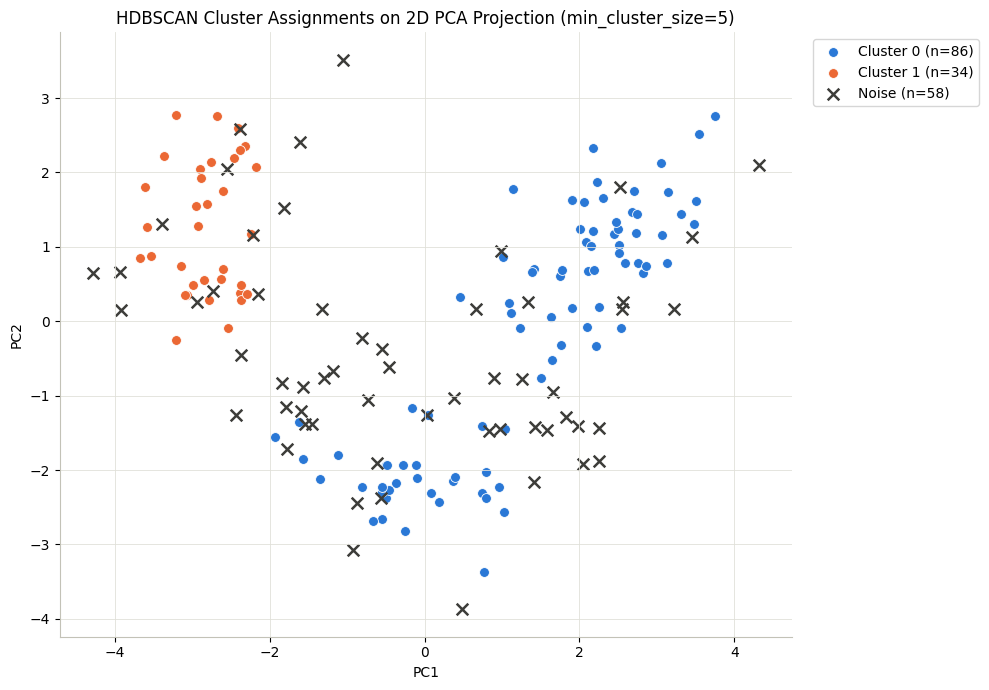

In [7]:
hdbscan_model = HDBSCAN(min_cluster_size=5, copy=True)
hdbscan_labels = hdbscan_model.fit_predict(X_scaled)

n_hdb_clusters = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
n_hdb_noise = int((hdbscan_labels == -1).sum())
print('HDBSCAN (min_cluster_size=5)')
print(f'Total clusters discovered: {n_hdb_clusters}')
print(f'Noise points detected:     {n_hdb_noise}')
print('Cluster sizes:', pd.Series(hdbscan_labels).value_counts().sort_index().to_dict())

plot_density_clusters(hdbscan_labels, 'HDBSCAN Cluster Assignments on 2D PCA Projection (min_cluster_size=5)')

HDBSCAN removes the need to choose eps; it explores all density levels and keeps the clusters that remain stable the longest. With min_cluster_size=5 it finds the cluster structure automatically and flags low-density wines as noise. This gives a result similar to the tuned DBSCAN but without manual eps tuning.

***Task 7***

Linkage matrix shape: (177, 4) (n-1 merges x [cluster_i, cluster_j, distance, size])


,cluster_i,cluster_j,merge distance,new cluster size
0,110.0,349.0,3.429,172.0
1,59.0,350.0,3.641,173.0
2,121.0,351.0,3.860,174.0
3,73.0,352.0,3.908,175.0
4,347.0,353.0,4.003,178.0


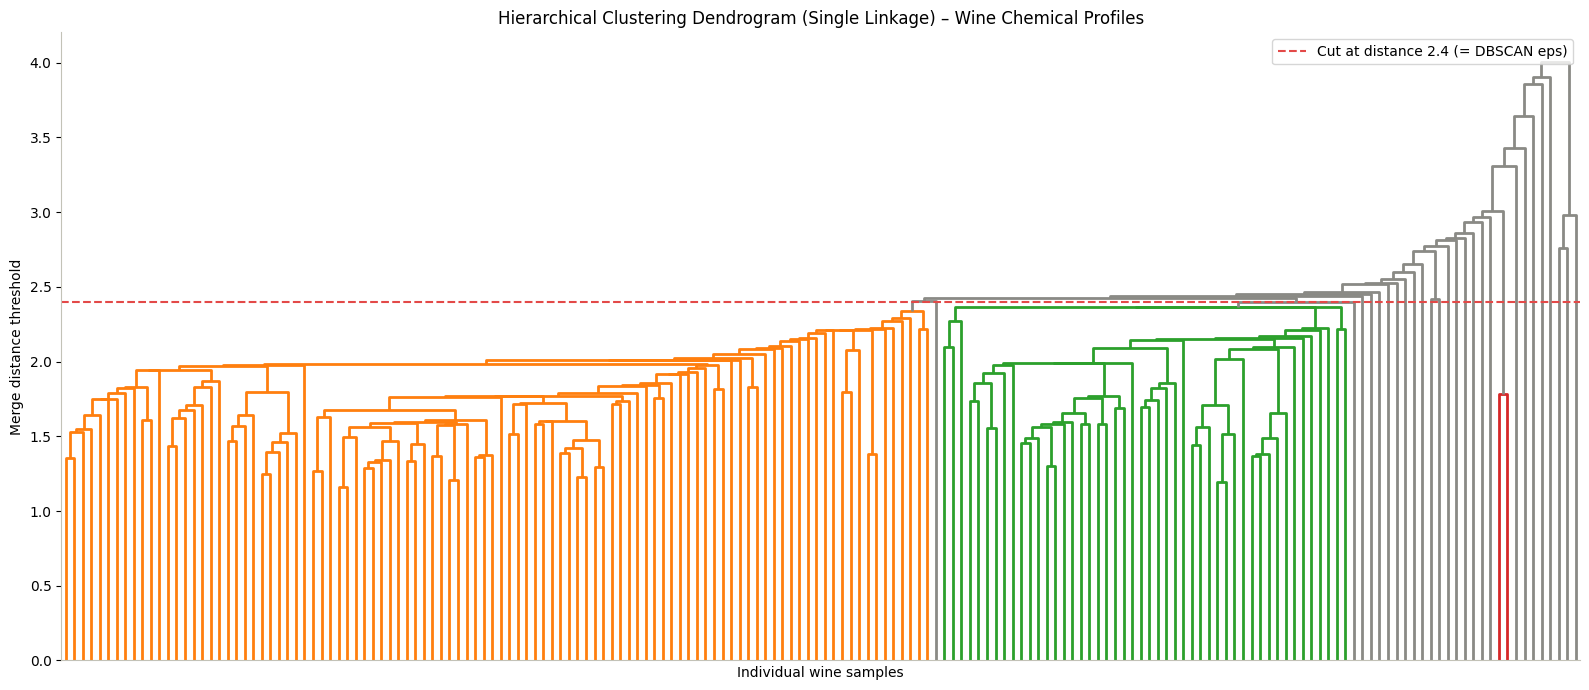

In [8]:
linkage_matrix = linkage(X_scaled, method='single', metric='euclidean')
print('Linkage matrix shape:', linkage_matrix.shape, '(n-1 merges x [cluster_i, cluster_j, distance, size])')
display(pd.DataFrame(linkage_matrix[-5:], columns=['cluster_i', 'cluster_j', 'merge distance', 'new cluster size']).round(3))

plt.figure(figsize=(16, 7))
dendrogram(linkage_matrix, orientation='top', distance_sort='descending', color_threshold=2.4,
           above_threshold_color='#8a8a85', no_labels=True)
plt.axhline(2.4, color='#e34948', linestyle='--', linewidth=1.5, label='Cut at distance 2.4 (= DBSCAN eps)')
plt.title('Hierarchical Clustering Dendrogram (Single Linkage) – Wine Chemical Profiles')
plt.xlabel('Individual wine samples')
plt.ylabel('Merge distance threshold')
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()

Summary:
Single linkage repeatedly merges the two closest points/groups and the dendrogram shows the distance at which every merge happens; cutting the tree horizontally at one height. HDBSCAN builds this same kind of single-linkage tree, condenses it by dropping branches smaller than min_cluster_size, and then extracts the branches that persist over the widest range of distances.

***Task 8***

Train size: 142, Test size: 36
Test class distribution: {0: 12, 1: 14, 2: 10}

K-Means (k=3)
true cultivar   0   1   2
cluster                  
0               0  65   0
1               0   3  48
2              59   3   0

DBSCAN (eps=2.4, min_samples=5)
true cultivar   0   1   2
cluster                  
-1              2  28   6
 0             57  42   0
 1              0   1  42

HDBSCAN (min_cluster_size=5)
true cultivar   0   1   2
cluster                  
-1              6  37  15
 0             53  33   0
 1              0   1  33

Summary:


,Algorithm,Clusters,Noise points,Test accuracy,Silhouette score
0,K-Means (k=3),3,0,0.9722,0.2849
1,"DBSCAN (eps=2.4, min_samples=5)",2,36,0.7778,0.3266
2,HDBSCAN (min_cluster_size=5),2,58,0.7500,0.3524


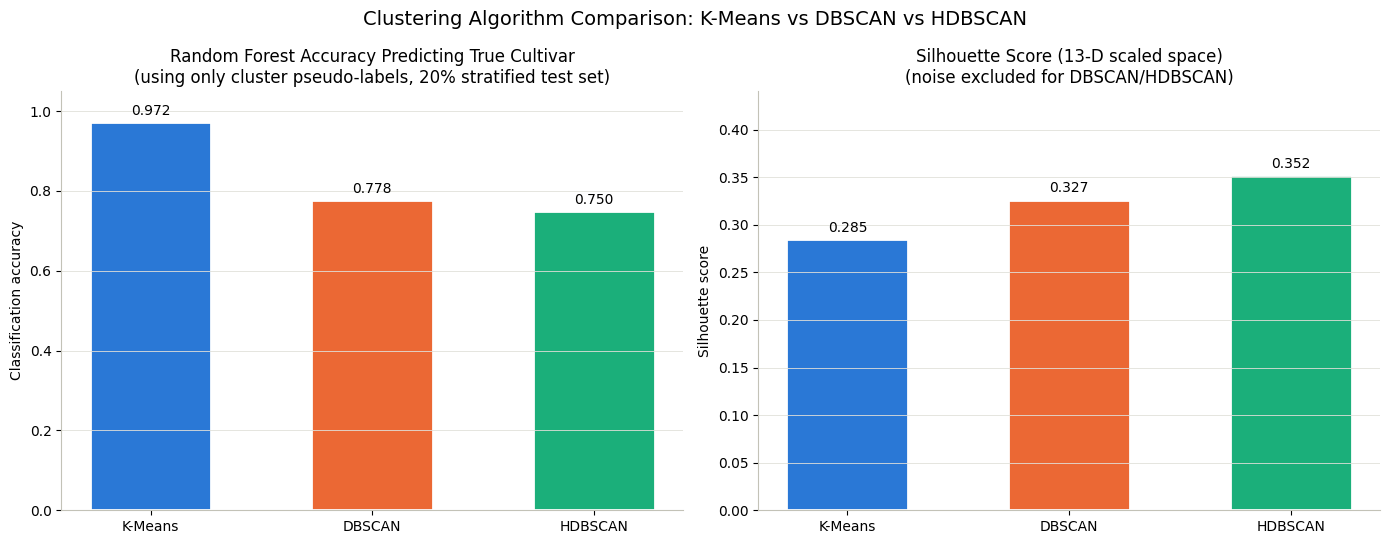

In [9]:
cluster_assignments = {
    'K-Means (k=3)': kmeans_labels,
    f'DBSCAN (eps={DB_EPS}, min_samples={DB_MIN_SAMPLES})': dbscan_labels,
    'HDBSCAN (min_cluster_size=5)': hdbscan_labels,
}

idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f'Train size: {len(idx_train)}, Test size: {len(idx_test)}')
print('Test class distribution:', y.iloc[idx_test].value_counts().sort_index().to_dict())

rows = []
for name, labels in cluster_assignments.items():
    enc = OneHotEncoder(handle_unknown='ignore')
    feat = labels.reshape(-1, 1)
    X_tr = enc.fit_transform(feat[idx_train])
    X_te = enc.transform(feat[idx_test])

    clf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
    clf.fit(X_tr, y.iloc[idx_train])
    acc = accuracy_score(y.iloc[idx_test], clf.predict(X_te))

    mask = labels != -1
    sil = silhouette_score(X_scaled[mask], labels[mask])
    rows.append({'Algorithm': name, 'Clusters': len(set(labels)) - (1 if -1 in labels else 0),
                 'Noise points': int((labels == -1).sum()), 'Test accuracy': acc, 'Silhouette score': sil})

    print(f'\n{name}')
    print(pd.crosstab(pd.Series(labels, name='cluster'), y, colnames=['true cultivar']))

summary = pd.DataFrame(rows)
print('\nSummary:')
display(summary.round(4))

short = ['K-Means', 'DBSCAN', 'HDBSCAN']
bar_colors = CLUSTER_COLORS[:3]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

b1 = ax1.bar(short, summary['Test accuracy'], color=bar_colors, width=0.55, edgecolor='white', linewidth=2)
ax1.bar_label(b1, labels=[f'{v:.3f}' for v in summary['Test accuracy']], padding=3)
ax1.set_ylim(0, 1.05)
ax1.set_title('Random Forest Accuracy Predicting True Cultivar\n(using only cluster pseudo-labels, 20% stratified test set)')
ax1.set_ylabel('Classification accuracy')

b2 = ax2.bar(short, summary['Silhouette score'], color=bar_colors, width=0.55, edgecolor='white', linewidth=2)
ax2.bar_label(b2, labels=[f'{v:.3f}' for v in summary['Silhouette score']], padding=3)
ax2.set_ylim(0, max(summary['Silhouette score']) * 1.25)
ax2.set_title('Silhouette Score (13-D scaled space)\n(noise excluded for DBSCAN/HDBSCAN)')
ax2.set_ylabel('Silhouette score')

for ax in (ax1, ax2):
    ax.grid(axis='x', visible=False)
plt.suptitle('Clustering Algorithm Comparison: K-Means vs DBSCAN vs HDBSCAN', fontsize=14)
plt.tight_layout()
plt.show()

Summary:
Each algorithm's cluster IDs are one-hot encoded and used as the only input to a Random Forest that predicts the real cultivar, using a stratified 80/20 split. High accuracy means the clusters line up with the true groups. K-Means (k=3) recovers the cultivars almost perfectly and also has a good silhouette, while DBSCAN and HDBSCAN only find 2 dense groups, so they cannot distinguish one cultivar pair and score lower on accuracy.